<a href="https://colab.research.google.com/github/yadavrishikesh/MA-563-Statistical-Computation-and-Simulation-/blob/main/code/module3/Practice_Lab_Bootstrap_Jackknife.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### MA 563 - Statistical Computation and Simulation
#### Lab 4: The Bootstrap and the Jackknife

Instructor: Dr. Rishikesh Yadav  |  TA: Vedant Vibhor

---

This lab is the computational companion to **Module 3**.

| Part | Topic | Slides |
|:--|:--|:--|
| 1 | The exact bootstrap for $\mathbf x=(2,5,9)$ | 10–15 |
| 2 | Nonparametric bootstrap of the mean, median and correlation: SE, bias, choosing $B$, intervals, $p$-values | 13, 16–19, 28–29, 36 |
| 3 | Parametric bootstrap of the same three statistics | 21–23, 36 |
| 4 | The jackknife for the mean and median: SE, bias, interval, $p$-value, and where it fails | 31–34 |

In [ ]:
# ------------------------------------------------------------------
# Setup: run this cell first.
# ------------------------------------------------------------------
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

BLUE, ORANGE, GREEN, RED, PURPLE = "#003366", "#ED7D31", "#2E7D32", "#C62828", "#6A1B9A"
LIGHTBLUE = "#CCD6E0"

rng = np.random.default_rng(seed=2026)

# Every (statistic, method) result is recorded here and shown together in Part 6.
RESULTS = {}

def record(statistic, method, estimate, se, bias, ci, h0, p):
    """Store estimate, SE, bias, 95% CI and p-value for the final table."""
    RESULTS[(statistic, method)] = {
        "estimate": round(float(estimate), 4), "SE": round(float(se), 4),
        "bias": round(float(bias), 4), "95% CI": f"[{ci[0]:.3f}, {ci[1]:.3f}]",
        "H0": h0, "p-value": round(float(p), 4)}

print("setup complete")

setup complete


---
### Part 1 - The Bootstrap Principle


### 1.1 A toy example by hand: $\mathbf x = (2, 5, 9)$ (slide 14)

With $n = 3$ there are only $3^3 = 27$ equally likely ordered resamples, so the **ideal**
bootstrap distribution of $\bar x^*$ can be computed exactly, with no simulation at all. Its
standard deviation is the plug-in quantity

$$\mathrm{se}_{\hat F_n}(\bar x^*) = \frac{\hat\sigma}{\sqrt n}, \qquad
\hat\sigma^2 = \frac1n\sum_{i=1}^n (x_i-\bar x)^2 \quad(\text{divisor } n),$$

which is smaller than the textbook $s/\sqrt n$ by the factor $\sqrt{(n-1)/n}$.

ordered resamples      : 27
exact bootstrap SE     : 1.6555
sigma_hat / sqrt(n)    : 1.6555   <- the same number
textbook s / sqrt(n)   : 2.0276
ratio                  : 0.8165   vs sqrt((n-1)/n) = 0.8165


,resample x*,orderings (of 27),probability,mean of x*
0,"(2, 2, 2)",1,0.0370,2.000
1,"(2, 2, 5)",3,0.1111,3.000
2,"(2, 2, 9)",3,0.1111,4.333
3,"(2, 5, 5)",3,0.1111,4.000
4,"(2, 5, 9)",6,0.2222,5.333
5,"(2, 9, 9)",3,0.1111,6.667
6,"(5, 5, 5)",1,0.0370,5.000
7,"(5, 5, 9)",3,0.1111,6.333
8,"(5, 9, 9)",3,0.1111,7.667
9,"(9, 9, 9)",1,0.0370,9.000


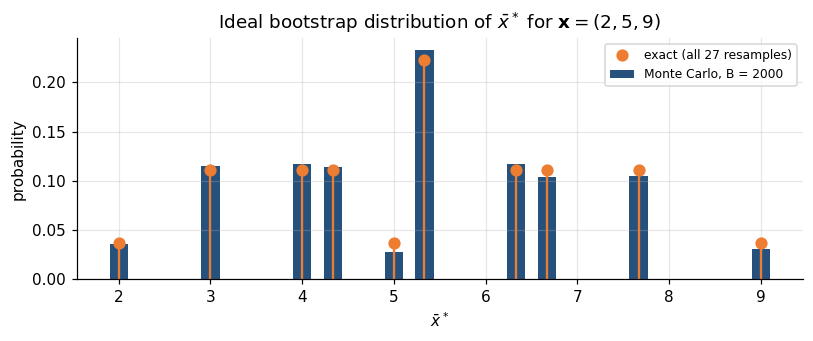

,ordered resamples n^n,"distinct resamples C(2n-1, n)"
n,,
3,27,10
10,1.00e+10,"92,378"
20,1.05e+26,6.89e+10
50,8.88e+84,5.04e+28


In [ ]:
# ------------------------------------------------------------------
# 1.1  One draw from F_hat = one index from {1,...,n}, via I = ceil(nU).
# ------------------------------------------------------------------

def resample(x, rng):
    """One bootstrap sample of size n from F_hat, by the discrete inverse transform."""
    x = np.asarray(x)
    n = len(x)
    u = 1.0 - rng.random(n)               # U in (0, 1], so ceil(nU) is in {1, ..., n}
    I = np.ceil(n * u).astype(int)        # I = ceil(nU), 1-based as on the slide
    return x[I - 1]                       # Python indexing is 0-based


# ------------------------------------------------------------------
# 1.2  Enumerate the whole bootstrap world for x = (2, 5, 9).
# ------------------------------------------------------------------
x_toy = np.array([2.0, 5.0, 9.0])
n_toy = len(x_toy)

all_resamples = np.array(list(itertools.product(x_toy, repeat=n_toy)))   # 27 rows
means_star = all_resamples.mean(axis=1)

se_exact = means_star.std()            # SD over 27 equally likely resamples (no B, no error)
print(f"ordered resamples      : {len(all_resamples)}")
print(f"exact bootstrap SE     : {se_exact:.4f}")
print(f"sigma_hat / sqrt(n)    : {x_toy.std() / np.sqrt(n_toy):.4f}   <- the same number")
print(f"textbook s / sqrt(n)   : {x_toy.std(ddof=1) / np.sqrt(n_toy):.4f}")
print(f"ratio                  : {se_exact / (x_toy.std(ddof=1) / np.sqrt(n_toy)):.4f}"
      f"   vs sqrt((n-1)/n) = {np.sqrt((n_toy - 1) / n_toy):.4f}")

# The 10 distinct resamples (as multisets) and how many of the 27 orderings give each one
ms = pd.Series([tuple(int(v) for v in sorted(r)) for r in all_resamples]).value_counts().sort_index()
display(pd.DataFrame({"resample x*": [str(m) for m in ms.index],
                      "orderings (of 27)": ms.values,
                      "probability": np.round(ms.values / 27, 4),
                      "mean of x*": [round(np.mean(m), 3) for m in ms.index]}))

# Exact distribution vs Monte Carlo inside the bootstrap world
B_toy = 2000
mc = np.round([resample(x_toy, rng).mean() for _ in range(B_toy)], 8)
vals, counts = np.unique(np.round(means_star, 8), return_counts=True)
mc_vals, mc_counts = np.unique(mc, return_counts=True)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(mc_vals, mc_counts / B_toy, width=0.2, color=BLUE, alpha=0.85,
       label=f"Monte Carlo, B = {B_toy}")
ax.vlines(vals, 0, counts / 27, color=ORANGE, lw=1.5)
ax.plot(vals, counts / 27, "o", color=ORANGE, ms=7, label="exact (all 27 resamples)")
ax.set_xlabel(r"$\bar x^*$"); ax.set_ylabel("probability")
ax.set_title(r"Ideal bootstrap distribution of $\bar x^*$ for $\mathbf{x} = (2, 5, 9)$")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# How big is the bootstrap world? (slide 15)
fmt = lambda v: f"{v:,}" if v < 10**7 else f"{v:.2e}"
display(pd.DataFrame([{"n": n, "ordered resamples n^n": fmt(n ** n),
                       "distinct resamples C(2n-1, n)": fmt(math.comb(2 * n - 1, n))}
                      for n in [3, 10, 20, 50]]).set_index("n"))

**What to notice.** The orange stems are the exact answer; the blue bars are what $B = 2000$
random resamples give. Beyond tiny $n$ the bootstrap world is far too big to enumerate, so we
always approximate it by Monte Carlo, and that adds a second layer of error (slide 15):

$$\underbrace{\mathrm{se}_F(\hat\theta)}_{\text{truth}}
\;\overset{\text{statistical error}}{\approx}\;
\underbrace{\mathrm{se}_{\hat F_n}(\hat\theta^*)}_{\text{ideal bootstrap}}
\;\overset{\text{Monte Carlo error}}{\approx}\;
\underbrace{\widehat{\mathrm{se}}_B}_{\text{what we compute}}$$

Increasing $B$ removes only the second error. We will measure both layers in Parts 2 and 4.

---
### Part 2 - The Nonparametric Bootstrap

#### 2.1 The algorithm (slides 13, 16, 29)

Given data $\mathbf x$ and a statistic $s(\cdot)$ with $\hat\theta = s(\mathbf x)$:

1. For $b = 1,\dots,B$: draw $\mathbf x^{*b}$ by sampling $n$ values **with replacement** from
   $\mathbf x$, and compute $\hat\theta^*_b = s(\mathbf x^{*b})$.
2. Use $\hat\theta^*_1,\dots,\hat\theta^*_B$ in place of the sampling distribution of $\hat\theta$.

With $\bar\theta^* = \frac1B\sum_b \hat\theta^*_b$,

$$\widehat{\mathrm{se}}_B = \sqrt{\frac{1}{B-1}\sum_{b=1}^B\big(\hat\theta^*_b-\bar\theta^*\big)^2},
\qquad \widehat{\mathrm{bias}}_B = \bar\theta^* - \hat\theta,$$

and two 95% intervals,

$$\text{Normal: }\ \hat\theta \pm 1.96\,\widehat{\mathrm{se}}_B,
\qquad \text{Percentile: }\ \big[\hat\theta^*_{(0.025)},\ \hat\theta^*_{(0.975)}\big].$$

The fourth quantity, a $p$-value,
needs resampling **under $H_0$** instead, and is the subject of Section 2.6.

The function below never looks inside $s(\cdot)$: it is a **black box**, and the same ten lines
serve the mean, the median and the correlation. For paired data, whole **rows** are resampled.

In [ ]:
# ------------------------------------------------------------------
# 2.1  The nonparametric bootstrap, plus a summary and a plot helper.
# ------------------------------------------------------------------

def bootstrap(data, stat, B):
    rng = np.random.default_rng(seed=2026)
    """Nonparametric bootstrap (slide 13).

    data : array of shape (n,) or (n, p). For (n, p), whole ROWS are resampled,
           so paired observations stay paired.
    stat : any function that maps a data set of that shape to a number.
    Returns the B replicates theta*_1, ..., theta*_B.
    """
    data = np.asarray(data)
    n = len(data)
    reps = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)   # n i.i.d. draws from F_hat (= ceil(nU) - 1)
        reps[b] = stat(data[idx])
    return reps


def boot_summary(theta_hat, reps, name=None, alpha=0.05, truth=None):
    """SE, bias, and the Normal and percentile intervals (slides 16 and 29).

    truth : the parameter's value in the bootstrap world, used for the bias. For the
            nonparametric bootstrap of a plug-in statistic this is theta_hat itself (default);
            for the parametric bootstrap it is the FITTED MODEL's value (see Part 3).
    """
    se = reps.std(ddof=1) ## setting denom as n-1
    bias = reps.mean() - (theta_hat if truth is None else truth)
    z = stats.norm.ppf(1 - alpha / 2)
    lo, hi = np.quantile(reps, [alpha / 2, 1 - alpha / 2])
    return pd.Series({
        "estimate": round(float(theta_hat), 4),
        "boot SE": round(float(se), 4),
        "boot bias": round(float(bias), 4),
        "|bias|/SE": round(float(abs(bias) / se), 3),
        "Normal 95% CI": f"[{theta_hat - z * se:.3f}, {theta_hat + z * se:.3f}]",
        "percentile 95% CI": f"[{lo:.3f}, {hi:.3f}]",
    }, name=name)


def plot_boot(ax, reps, theta_hat, title, xlabel, bins=50, color=BLUE):
    """Histogram of the replicates with theta_hat and the 95% percentile interval."""
    lo, hi = np.quantile(reps, [0.025, 0.975])
    ax.hist(reps, bins=bins, density=True, color=color, edgecolor="white", alpha=0.85,
            label="bootstrap replicates")
    ax.axvspan(lo, hi, color=ORANGE, alpha=0.12, label="95% percentile interval")
    ax.axvline(theta_hat, color=GREEN, lw=2.2, label=r"$\hat\theta$")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("density")

print("bootstrap(), boot_summary(), plot_boot() defined")

bootstrap(), boot_summary(), plot_boot() defined


### 2.2 Statistic 1 - the mean: hospital length of stay (slide 17)

Length of stay (days) for $n = 20$ patients: a small, right-skewed sample. For the mean we
already know the answer, $s/\sqrt n$: the bootstrap
should reproduce the ideal value $\hat\sigma/\sqrt n = \sqrt{19/20}\; s/\sqrt n$ up to Monte
Carlo error.

x_bar = 4.150,  s = 2.617
classical      s / sqrt(n)        = 0.5853
bootstrap      se_B  (B = 4999)   = 0.5750


,estimate,boot SE,boot bias,|bias|/SE,Normal 95% CI,percentile 95% CI
mean,4.15,0.575,-0.0101,0.018,"[3.023, 5.277]","[3.090, 5.315]"


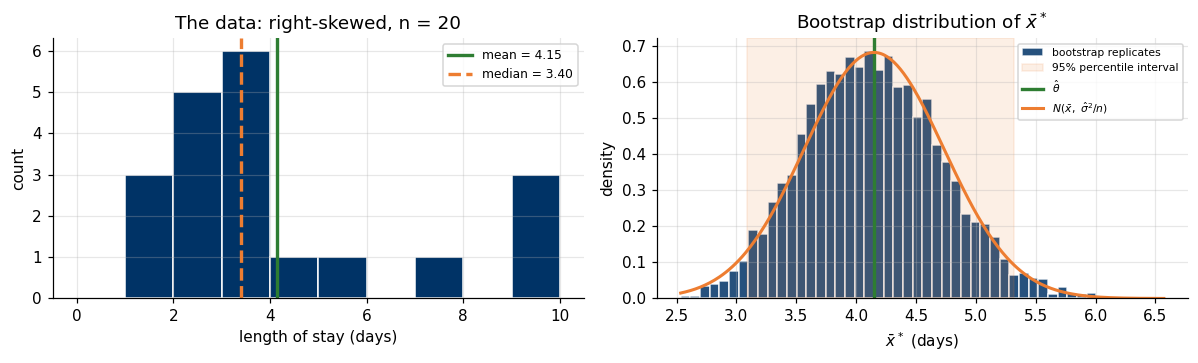

In [ ]:
# ------------------------------------------------------------------
# 2.2  Bootstrap the mean of the length-of-stay data.
# ------------------------------------------------------------------
los = np.array([1.2, 1.3, 1.7, 2.0, 2.2, 2.2, 2.7, 2.9, 3.2, 3.2,
                3.6, 3.8, 3.9, 3.9, 4.6, 5.7, 7.3, 9.0, 9.3, 9.3])   # days (slide 17)
n_los = len(los)
B = 4999

mean_hat = los.mean()
reps_mean = bootstrap(los, np.mean, B)

se_classical = los.std(ddof=1) / np.sqrt(n_los)

print(f"x_bar = {mean_hat:.3f},  s = {los.std(ddof=1):.3f}")
print(f"classical      s / sqrt(n)        = {se_classical:.4f}")
print(f"bootstrap      se_B  (B = {B})   = {reps_mean.std(ddof=1):.4f}")
display(boot_summary(mean_hat, reps_mean, name="mean").to_frame().T)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(los, bins=np.arange(0, 10.5, 1), color=BLUE, edgecolor="white")
ax[0].axvline(mean_hat, color=GREEN, lw=2.2, label=f"mean = {mean_hat:.2f}")
ax[0].axvline(np.median(los), color=ORANGE, lw=2.2, ls="--",
              label=f"median = {np.median(los):.2f}")
ax[0].set_title("The data: right-skewed, n = 20")
ax[0].set_xlabel("length of stay (days)"); ax[0].set_ylabel("count"); ax[0].legend(fontsize=8)

plot_boot(ax[1], reps_mean, mean_hat, r"Bootstrap distribution of $\bar x^*$", r"$\bar x^*$ (days)")
g = np.linspace(reps_mean.min(), reps_mean.max(), 300)
ax[1].plot(g, stats.norm(mean_hat, se_classical).pdf(g), color=ORANGE, lw=2,
           label=r"$N(\bar x,\ \hat\sigma^2/n)$")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

*Try:* set `B = 50` and re-run the cell a few times. Watch $\widehat{\mathrm{se}}_B$ jump around.
That is the Monte Carlo layer, which the next section measures.

### 2.3 Statistic 2 - the median (slides 5, 17)

The classical route needs the density at the median, $\mathrm{se}(\hat m) \approx
1/\{2 f(m)\sqrt n\}$, and $f$ is unknown. Plugging in a kernel density estimate gives an answer
that depends on the bandwidth you chose. The bootstrap needs nothing new: same
function, different black box.

,estimate,boot SE,boot bias,|bias|/SE,Normal 95% CI,percentile 95% CI
median,3.4,0.4948,0.0294,0.059,"[2.430, 4.370]","[2.450, 4.250]"


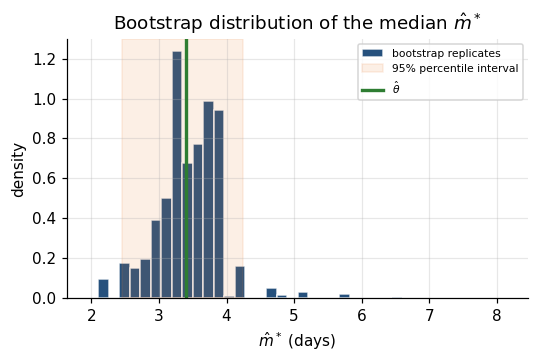

In [ ]:
# ------------------------------------------------------------------
# 2.3  Bootstrap the median; compare with the plug-in formula.
# ------------------------------------------------------------------
med_hat = np.median(los)
reps_med = bootstrap(los, np.median, B)

display(boot_summary(med_hat, reps_med, name="median").to_frame().T)

vals, counts = np.unique(reps_med, return_counts=True)
fig, ax = plt.subplots(1, 1, figsize=(5, 3.4))
plot_boot(ax, reps_med, med_hat, r"Bootstrap distribution of the median $\hat m^*$",
          r"$\hat m^*$ (days)", bins=40)
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** The bootstrap distribution of the median is **lumpy**: every $\hat m^*$ is
either a data value or the midpoint of two, so only a few dozen values are possible. The
SE is still well defined, and it needs no density estimate. The median is not a smooth statistic, which is why the theory
on slide 18 needs care here; Part 4 checks how well the bootstrap does against the truth.

### 2.4 Statistic 3 - the sample correlation: law school data

Average LSAT score and undergraduate GPA for 15 American law schools, the classic first
bootstrap example for $r$ (Efron & Tibshirani, 1993, Ch. 3). Classical theory for $r$ assumes
bivariate Normality:

Fisher's $z = \operatorname{artanh}(r) \approx
N\big(\operatorname{artanh}\rho,\ 1/(n-3)\big)$

gives the delta-method SE
$(1-r^2)/\sqrt{n-3}$ and the interval $\tanh\big(z \pm 1.96/\sqrt{n-3}\big)$.

For the bootstrap, the resampling unit is the **school**, the pair $(x_i, y_i)$. Resampling the
two columns separately would destroy the relationship we are trying to measure; the
second histogram below shows what that does.

r = 0.7764
Fisher-z (bivariate Normal):  SE = 0.1147,  95% CI = [0.439, 0.922]


,estimate,boot SE,boot bias,|bias|/SE,Normal 95% CI,percentile 95% CI
correlation,0.7764,0.1357,-0.008,0.059,"[0.510, 1.042]","[0.447, 0.961]"


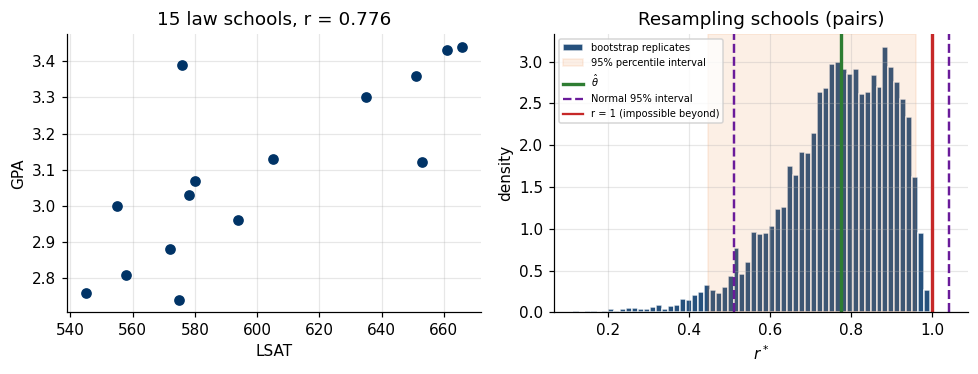

In [ ]:
# ------------------------------------------------------------------
# 2.4  Bootstrap the correlation: resample PAIRS.
# ------------------------------------------------------------------
lsat = np.array([576, 635, 558, 578, 666, 580, 555, 661, 651, 605, 653, 575, 545, 572, 594.])
gpa  = np.array([3.39, 3.30, 2.81, 3.03, 3.44, 3.07, 3.00, 3.43, 3.36, 3.13,
                 3.12, 2.74, 2.76, 2.88, 2.96])
law = np.column_stack([lsat, gpa])              # one ROW per school
n_law = len(law)

def corr(d):
    """Sample correlation of an (n, 2) data set."""
    return np.corrcoef(d[:, 0], d[:, 1])[0, 1]

r_hat = corr(law)
reps_r = bootstrap(law, corr, B)           # resample schools (rows)


z_hat, half = np.arctanh(r_hat), 1.96 / np.sqrt(n_law - 3)

print(f"r = {r_hat:.4f}")
print(f"Fisher-z (bivariate Normal):  SE = {(1 - r_hat**2) / np.sqrt(n_law - 3):.4f},"
      f"  95% CI = [{np.tanh(z_hat - half):.3f}, {np.tanh(z_hat + half):.3f}]")
display(boot_summary(r_hat, reps_r, name="correlation").to_frame().T)

se_r = reps_r.std(ddof=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(lsat, gpa, "o", color=BLUE, ms=6)
ax[0].set_xlabel("LSAT"); ax[0].set_ylabel("GPA"); ax[0].set_title(f"15 law schools, r = {r_hat:.3f}")

plot_boot(ax[1], reps_r, r_hat, "Resampling schools (pairs)", r"$r^*$", bins=60)
for e in (r_hat - 1.96 * se_r, r_hat + 1.96 * se_r):
    ax[1].axvline(e, color=PURPLE, ls="--", lw=1.6)
ax[1].axvline(1.0, color=RED, lw=2.2)
ax[1].plot([], [], color=PURPLE, ls="--", label="Normal 95% interval")
ax[1].plot([], [], color=RED, label="r = 1 (impossible beyond)")
ax[1].legend(fontsize=6.5, loc="upper left")

plt.tight_layout(); plt.show()

**What to notice.**

* $r^*$ is bounded by 1, so its bootstrap distribution is **skewed to the left**. The Normal
  interval ignores this and reaches **beyond 1**, a correlation that cannot exist. The percentile
  interval is built from correlations, so it stays inside $[-1, 1]$; it is *transformation
  respecting* (slide 29).

### 2.5 $p$-values: simulate under $H_0$ (slide 36)

A confidence interval comes from the bootstrap distribution around $\hat\theta$. A $p$-value
needs the distribution of the statistic **when $H_0$ is true**. The Monte Carlo test of slide 36:

1. compute $t_{\text{obs}} = T(\mathbf x)$;
2. for $b = 1,\dots,B$, simulate $\mathbf x^{*b}$ **under $H_0$** and compute $T^*_b$;
3. return $\displaystyle \hat p = \frac{1 + \#\{b : T^*_b \ge t_{\text{obs}}\}}{B+1}$.

We use the two-sided statistic $T = |\hat\theta - \theta_0|$. The only real decision is how to
make the resampled data obey $H_0$ without assuming a model:

| Statistic | $H_0$ | How the resampling obeys $H_0$ |
|:--|:--|:--|
| mean | $\mu = 3$ days | **shift** the data, $\tilde x_i = x_i - \bar x + 3$, then resample $\tilde{\mathbf x}$ |
| median | $m = 3$ days | shift by the median, $\tilde x_i = x_i - \hat m + 3$, then resample |
| correlation | $\rho = 0$ | **break the pairs**: resample LSAT and GPA independently |

The shift keeps the shape and spread of the data and moves only its centre onto $H_0$. Each
bootstrap $p$-value is set beside the classical test for the same hypothesis.

,H0,t_obs = |theta_hat - theta0|,bootstrap p (B = 4999),classical test,classical p
mean,mu = 3 days,1.1500,0.0430,one-sample t,0.0642
median,m = 3 days,0.4000,0.3524,sign test (exact binomial),0.5034
correlation,rho = 0,0.7764,0.0014,"Pearson t, n-2 df",0.0007


smallest possible bootstrap p-value with B = 4999: 1/(B+1) = 0.0002


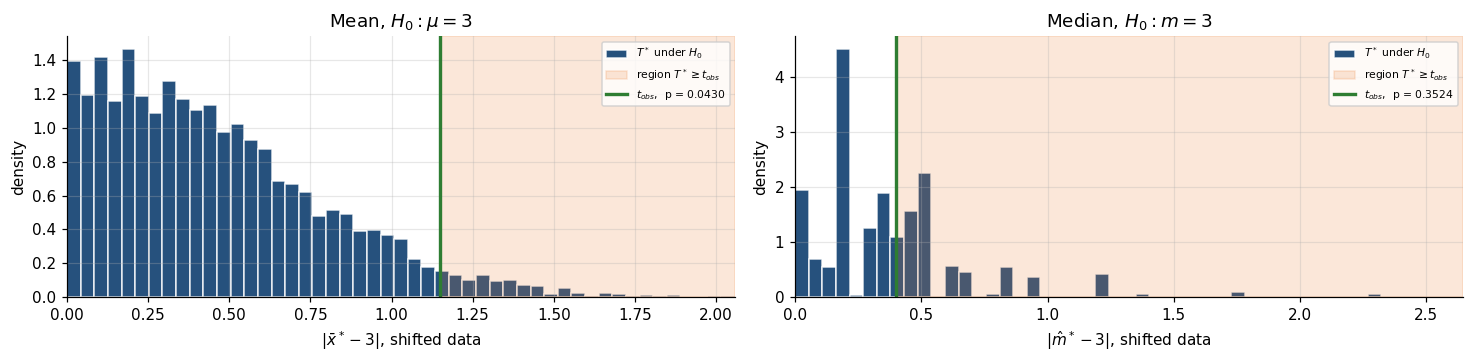

In [ ]:
# ------------------------------------------------------------------
# 2.5  Monte Carlo p-values for the mean, median and correlation.
# ------------------------------------------------------------------

def mc_pvalue(t_obs, t_null):
    """Monte Carlo p-value (slide 36): (1 + #{T*_b >= t_obs}) / (B + 1)."""
    t_null = np.asarray(t_null)
    return (1 + np.sum(t_null >= t_obs)) / (len(t_null) + 1)


def boot_test_location(x, stat, theta0, B):
    """Nonparametric bootstrap test of H0: theta = theta0 for a LOCATION statistic.

    The data are shifted so that stat(shifted data) = theta0 exactly, then resampled.
    Test statistic T = |stat - theta0|. Returns (p-value, t_obs, T* under H0).
    """
    x = np.asarray(x)
    x0 = x - stat(x) + theta0                      # the data, moved onto H0
    t_obs = abs(stat(x) - theta0)
    t_null = np.abs(bootstrap(x0, stat, B) - theta0)
    return mc_pvalue(t_obs, t_null), t_obs, t_null


MU0 = 3.0                                          # H0 for both mean and median: 3 days
p_mean, t_mean, null_mean = boot_test_location(los, np.mean, MU0, B)
p_med,  t_med,  null_med  = boot_test_location(los, np.median, MU0, B)

# Wrong: resample LSAT and GPA independently of each other
reps_r_wrong = np.array([corr(np.column_stack([resample(lsat, rng), resample(gpa, rng)]))
                         for _ in range(B)])

p_r, t_r, null_r = mc_pvalue(abs(r_hat), np.abs(reps_r_wrong)), abs(r_hat), np.abs(reps_r_wrong)

# the classical tests of the same hypotheses
p_t = stats.ttest_1samp(los, MU0).pvalue                                   # one-sample t
n_below, n_diff = int(np.sum(los < MU0)), int(np.sum(los != MU0))
p_sign = stats.binomtest(n_below, n_diff, 0.5).pvalue                      # sign test
p_pearson = stats.pearsonr(lsat, gpa).pvalue                               # t-test for rho

display(pd.DataFrame({
    "H0": ["mu = 3 days", "m = 3 days", "rho = 0"],
    "t_obs = |theta_hat - theta0|": [t_mean, t_med, t_r],
    f"bootstrap p (B = {B})": [p_mean, p_med, p_r],
    "classical test": ["one-sample t", "sign test (exact binomial)", "Pearson t, n-2 df"],
    "classical p": [p_t, p_sign, p_pearson],
}, index=["mean", "median", "correlation"]).round(4))
print(f"smallest possible bootstrap p-value with B = {B}: 1/(B+1) = {1 / (B + 1):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 3.4))
for a, null, t, p, lab in [(ax[0], null_mean, t_mean, p_mean, r"$|\bar x^* - 3|$, shifted data"),
                           (ax[1], null_med, t_med, p_med, r"$|\hat m^* - 3|$, shifted data")]:
                        #    (ax[2], null_r, t_r, p_r, r"$|r^*|$, pairs broken")]:
    hi = max(np.quantile(null, 0.998), t) * 1.15
    bins = np.linspace(0, hi, 50)
    a.hist(null, bins=bins, density=True, color=BLUE, edgecolor="white", alpha=0.85,
           label=r"$T^*$ under $H_0$")
    a.axvspan(t, hi, color=ORANGE, alpha=0.18, label=r"region $T^* \geq t_{obs}$")
    a.axvline(t, color=GREEN, lw=2.2, label=rf"$t_{{obs}}$,  p = {p:.4f}")
    a.set_xlim(0, hi)
    a.set_xlabel(lab); a.set_ylabel("density"); a.legend(fontsize=7)
ax[0].set_title(r"Mean, $H_0: \mu = 3$"); ax[1].set_title(r"Median, $H_0: m = 3$")
# ax[2].set_title(r"Correlation, $H_0: \rho = 0$")
plt.tight_layout(); plt.show()

**What to notice.**

* **Mean:** the bootstrap $p$ is close to the $t$-test's, and both sit near 0.05. That is
  borderline evidence that stays exceed 3 days. The bootstrap $p$ is smaller because
  resampling uses the divisor-$n$ spread $\hat\sigma$ (the $\sqrt{(n-1)/n}$ factor again).
* **Median:** no evidence against $m = 3$, in agreement with the sign test. The sign test
  needs no resampling, but it exists only for the median; the shift bootstrap works for any
  location statistic.
* **Correlation:** only a handful of the $B$ replicates reach $|\hat r| = 0.776$, so the bootstrap
  $p$ is near its floor $1/(B+1)$. For a $p$-value this small, Monte Carlo resolution matters:
  this is why slide 19 recommends $B = 999$ or $9999$ for tests.

In [ ]:
# ------------------------------------------------------------------
# 2.7  One row per statistic: SE, bias, 95% CIs, p-value.
# ------------------------------------------------------------------
part2 = pd.concat([boot_summary(mean_hat, reps_mean, name="mean (LOS)"),
                   boot_summary(med_hat, reps_med, name="median (LOS)"),
                   boot_summary(r_hat, reps_r, name="correlation (law)")], axis=1).T
part2["H0"] = ["mu = 3", "m = 3", "rho = 0"]
part2["bootstrap p"] = [round(p_mean, 4), round(p_med, 4), round(p_r, 4)]
display(part2)


for stat_name, est, reps, h0, p in [("mean (LOS)", mean_hat, reps_mean, "mu = 3", p_mean),
                                    ("median (LOS)", med_hat, reps_med, "m = 3", p_med),
                                    ("correlation (law)", r_hat, reps_r, "rho = 0", p_r)]:
    record(stat_name, "nonparametric bootstrap", est, reps.std(ddof=1), reps.mean() - est,
           np.quantile(reps, [0.025, 0.975]), h0, p)



for stat_name, est, reps, h0, p in [("mean (LOS)", mean_hat, reps_mean, "mu = 3", p_mean),
                                    ("median (LOS)", med_hat, reps_med, "m = 3", p_med),
                                    ("correlation (law)", r_hat, reps_r, "rho = 0", p_r)]:
    record(stat_name, "nonparametric bootstrap", est, reps.std(ddof=1), reps.mean() - est,
           np.quantile(reps, [0.025, 0.975]), h0, p)

,estimate,boot SE,boot bias,|bias|/SE,Normal 95% CI,percentile 95% CI,H0,bootstrap p
mean (LOS),4.15,0.575,-0.0101,0.018,"[3.023, 5.277]","[3.090, 5.315]",mu = 3,0.0430
median (LOS),3.4,0.4948,0.0294,0.059,"[2.430, 4.370]","[2.450, 4.250]",m = 3,0.3524
correlation (law),0.7764,0.1357,-0.008,0.059,"[0.510, 1.042]","[0.447, 0.961]",rho = 0,0.0014


---
### Part 3 - The Parametric Bootstrap

#### 3.1 The algorithm (slide 21)

If we trust a parametric model $\{F_\theta\}$, estimate $F$ by $F_{\hat\theta}$ instead of
$\hat F_n$, and **simulate new data** from it with the generators of Module 1:

1. Fit the model: $\hat\theta$ (usually the MLE) from $\mathbf x$.
2. For $b = 1,\dots,B$: simulate $x^{*b}_1,\dots,x^{*b}_n \overset{iid}{\sim} F_{\hat\theta}$
   and recompute the statistic, $\hat\theta^*_b$.
3. Use $\hat\theta^*_1,\dots,\hat\theta^*_B$ exactly as in Part 2.

Only one line of the algorithm changes: *resample the observed values* becomes *generate new
values from the fitted model*. In the code, the simulator is the only new thing.

SE and intervals come from `boot_summary()` exactly as before. The **bias** needs one line of
care. Slide 16's plug-in rule replaces the true $\theta$ by its value *in the bootstrap principle*.

For a $p$-value the model makes "simulate under $H_0$" (slide 36) straightforward: simulate from
the model with its parameter **set to satisfy $H_0$**, and compute $T^* = |\hat\theta^* - \theta_0|$.

In [ ]:
# ------------------------------------------------------------------
# 3.1  The parametric bootstrap.
# ------------------------------------------------------------------

def parametric_bootstrap(simulate, stat, B):

    rng = np.random.default_rng(seed=2026)

    """Parametric bootstrap (slide 21).

    simulate : function rng -> one synthetic data set of size n from the FITTED model
    stat     : the statistic, recomputed on every synthetic data set
    """
    reps = np.empty(B)
    for b in range(B):
        reps[b] = stat(simulate(rng))
    return reps

print("parametric_bootstrap() defined")

parametric_bootstrap() defined


### 3.2 Mean and median of the hospital data under Lognormal model


| Model | MLE | Simulator (Module 1) |
|:--|:--|:--|
| Lognormal $(\mu,\sigma^2)$ | $\hat\mu,\hat\sigma$ = mean and SD (divisor $n$) of $\log x_i$ | $X^* = \exp(\hat\mu + \hat\sigma Z)$ |

We bootstrap the **sample mean** and **sample median**, the same statistics as in Part 2, and
compare with the nonparametric answers (Slide 23).

For the $p$-values ($H_0$: mean $= 3$ days, median $= 3$ days) each model is re-set to satisfy
$H_0$, keeping its shape parameter at the fitted value:

| Model | $H_0$: mean $= 3$ | $H_0$: median $= 3$ |
|:--|:--|:--|
| Lognormal (mean $e^{\mu+\sigma^2/2}$, median $e^{\mu}$) | $\mu_0 = \ln 3 - \hat\sigma^2/2,\ \sigma = \hat\sigma$ | $\mu_0 = \ln 3,\ \sigma = \hat\sigma$ |

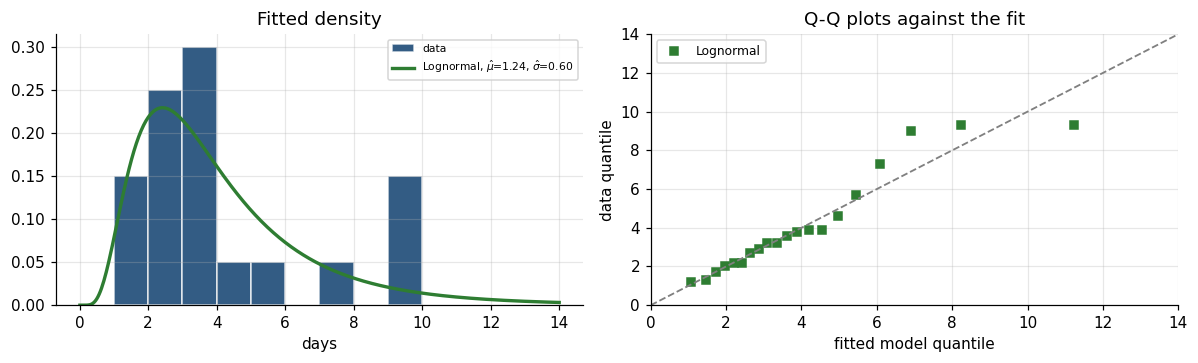

boot SE  boot bias  |bias|/SE  \
statistic method                                                  
mean      nonparametric (Part 2)   0.5750    -0.0101      0.018   
          parametric: Lognormal    0.6046    -0.0051      0.008   
median    nonparametric (Part 2)   0.4948     0.0294      0.059   
          parametric: Lognormal    0.5701     0.0514      0.090   

                                 percentile 95% CI  bias reference  \
statistic method                                                     
mean      nonparametric (Part 2)    [3.090, 5.315]           4.150   
          parametric: Lognormal     [3.121, 5.472]           4.153   
median    nonparametric (Part 2)    [2.450, 4.250]           3.400   
          parametric: Lognormal     [2.527, 4.761]           3.469   

                                  p (H0: 3 days)  
statistic method                                  
mean      nonparametric (Part 2)          0.0430  
          parametric: Lognormal           0.0122  
median    nonparametric (Part 2)          0.3524  
          parametric: Lognormal           0.4054

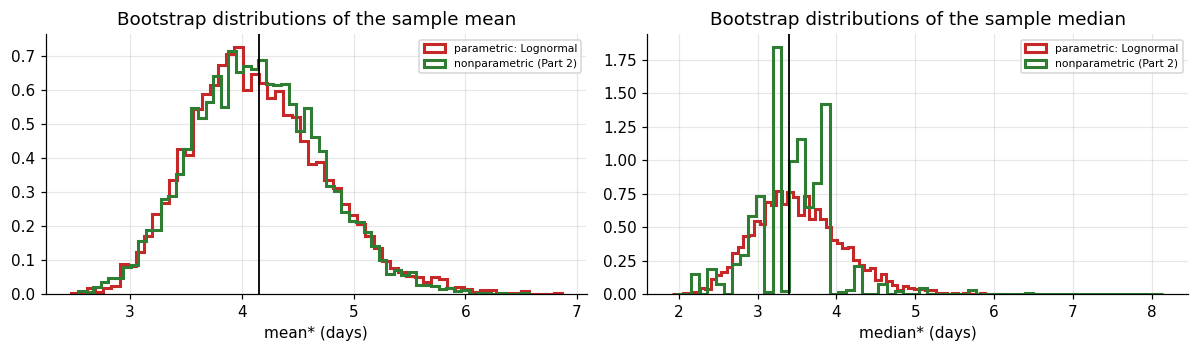

In [ ]:
# ------------------------------------------------------------------
# 3.2  Hospital data: fit the model, then bootstrap
# ------------------------------------------------------------------
mu_los, sig_los = np.log(los).mean(), np.log(los).std()          # lognormal MLE

sim_los_ln  = lambda rng: np.exp(mu_los + sig_los * rng.standard_normal(n_los))


fit_ln  = stats.lognorm(s=sig_los, scale=np.exp(mu_los))

# --- model check before trusting the model --------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
g = np.linspace(0.01, 14, 400)
ax[0].hist(los, bins=np.arange(0, 10.5, 1), density=True, color=BLUE, edgecolor="white",
           alpha=0.8, label="data")
ax[0].plot(g, fit_ln.pdf(g), color=GREEN, lw=2.2,
           label=rf"Lognormal, $\hat\mu$={mu_los:.2f}, $\hat\sigma$={sig_los:.2f}")
ax[0].set_title("Fitted density"); ax[0].set_xlabel("days"); ax[0].legend(fontsize=7)

p = (np.arange(1, n_los + 1) - 0.5) / n_los
ax[1].plot(fit_ln.ppf(p), np.sort(los), "s", color=GREEN, ms=5, label="Lognormal")
ax[1].plot([0, 14], [0, 14], "--", color="gray", lw=1.2)
ax[1].set_xlim(0, 14); ax[1].set_ylim(0, 14)
ax[1].set_xlabel("fitted model quantile"); ax[1].set_ylabel("data quantile")
ax[1].set_title("Q-Q plots against the fit"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


# --- the bootstraps: SE, bias, CI from the fitted model ----------
reps_par = {
    "parametric: Lognormal":   {s: parametric_bootstrap(sim_los_ln, f, B)
                                for s, f in [("mean", np.mean), ("median", np.median)]},
    "nonparametric (Part 2)":  {"mean": reps_mean, "median": reps_med},
}

# --- p-values: simulate from each model re-set to satisfy H0 -----
sim_H0 = {
    ("parametric: Lognormal", "mean"):     lambda rng: np.exp(np.log(MU0) - sig_los**2 / 2
                                                              + sig_los * rng.standard_normal(n_los)),
    ("parametric: Lognormal", "median"):   lambda rng: np.exp(np.log(MU0) + sig_los * rng.standard_normal(n_los)),
}
stat_fn = {"mean": np.mean, "median": np.median}
est = {"mean": mean_hat, "median": med_hat}
pvals = {("nonparametric (Part 2)", "mean"): p_mean, ("nonparametric (Part 2)", "median"): p_med}
for (m, s), sim in sim_H0.items():
    pvals[(m, s)] = mc_pvalue(abs(est[s] - MU0),
                              np.abs(parametric_bootstrap(sim, stat_fn[s], B) - MU0))

# bias reference: the fitted model's own mean / median (Section 3.1); data values for nonparametric
model_value = {
    ("parametric: Lognormal", "mean"): np.exp(mu_los + sig_los**2 / 2),
    ("parametric: Lognormal", "median"): np.exp(mu_los),
}

rows = []
for m, d in reps_par.items():
    for s, reps in d.items():
        ref = model_value.get((m, s), est[s])
        row = boot_summary(est[s], reps, name=(s, m), truth=ref).drop(["estimate", "Normal 95% CI"])
        row.loc["bias reference"] = round(float(ref), 3)
        row.loc["p (H0: 3 days)"] = round(pvals[(m, s)], 4)
        rows.append(row)
        if m != "nonparametric (Part 2)":
            record(f"{s} (LOS)", m.replace("parametric: ", "parametric bootstrap (") + ")", est[s],
                   reps.std(ddof=1), reps.mean() - ref, np.quantile(reps, [0.025, 0.975]),
                   f"{'mu' if s == 'mean' else 'm'} = 3", pvals[(m, s)])
display(pd.DataFrame(rows, index=pd.MultiIndex.from_tuples([r.name for r in rows],
                                                          names=["statistic", "method"])).sort_index())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for j, s in enumerate(["mean", "median"]):
    for m, c in zip(reps_par, [RED, GREEN, BLUE]):
        ax[j].hist(reps_par[m][s], bins=60, density=True, histtype="step", lw=2, color=c, label=m)
    ax[j].axvline(mean_hat if s == "mean" else med_hat, color="black", lw=1.2)
    ax[j].set_title(f"Bootstrap distributions of the sample {s}")
    ax[j].set_xlabel(f"{s}* (days)")
ax[0].legend(fontsize=7)
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The **bias** column is now the model-bias, measured from the model's own mean or median
(shown as *bias reference*). The Lognormal median's reference $e^{\hat\mu}$ is not the sample
median 3.4.

### 3.3 Correlation under a bivariate Normal model

Fit $(\hat{\boldsymbol\mu}, \hat\Sigma)$ by maximum likelihood (divisor $n$) and simulate $n$
pairs at a time as $\hat{\boldsymbol\mu} + L\mathbf Z$, where $LL^\top = \hat\Sigma$ (Cholesky)
and $\mathbf Z$ is a pair of independent $N(0,1)$ draws. Lab 2's Box–Muller would supply these;
we use `rng.standard_normal`.

This setting has an exact answer too. Under a bivariate Normal with correlation $\rho$, $r$ has
the density (Fisher, 1915, in Hotelling's form)

$$f(r;\rho,n)=\frac{(n-2)\,\Gamma(n-1)\,(1-\rho^2)^{(n-1)/2}\,(1-r^2)^{(n-4)/2}}
{\sqrt{2\pi}\;\Gamma(n-\tfrac12)\,(1-\rho r)^{n-3/2}}\;
{}_2F_1\!\Big(\tfrac12,\tfrac12;\,n-\tfrac12;\,\tfrac{1+\rho r}{2}\Big),$$

and with $\rho = \hat r$ this is the exact parametric-bootstrap distribution, which we can
overlay.

**Test of $H_0: \rho = 0$.** Under the bivariate Normal model, $\rho = 0$ means the two
coordinates are independent Normals, so we simulate them with the fitted means and variances
and zero correlation. The classical Pearson $t$-test is *exact* under this model, so the
parametric bootstrap $p$-value has a ground truth to hit.

,SE,bias,95% CI,p (H0: rho = 0)
Fisher-z / Pearson t (formula),0.1147,—,"[0.439, 0.922]",0.0007
nonparametric bootstrap,0.1357,-0.008,"[0.447, 0.961]",0.0014
parametric bootstrap (biv. Normal),0.1191,-0.0101,"[0.461, 0.926]",0.0006


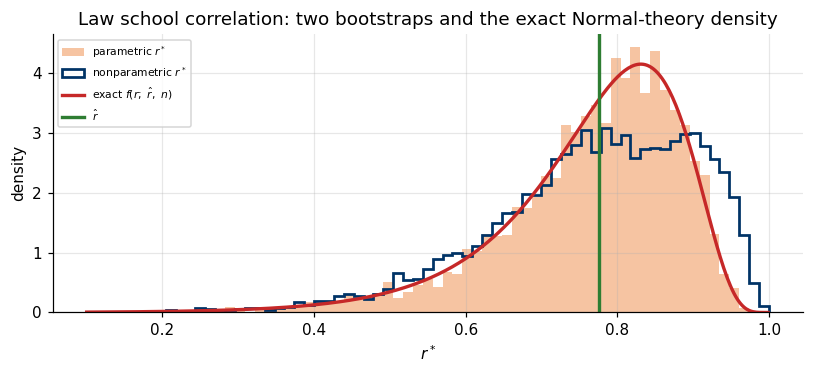

In [ ]:
# ------------------------------------------------------------------
# 3.3  Correlation: parametric (bivariate Normal) vs nonparametric bootstrap.
# ------------------------------------------------------------------
mu_law = law.mean(axis=0)
Sigma_law = np.cov(law, rowvar=False, ddof=0)              # MLE: divisor n
L_law = np.linalg.cholesky(Sigma_law)
sim_law = lambda rng: mu_law + rng.standard_normal((n_law, 2)) @ L_law.T

reps_r_par = parametric_bootstrap(sim_law, corr, B)


def r_pdf(r, rho, n):
    """Exact density of the sample correlation under a bivariate Normal (Hotelling's form)."""
    lg = special.gammaln
    log_c = np.log(n - 2) + lg(n - 1) - 0.5 * np.log(2 * np.pi) - lg(n - 0.5)
    log_f = (log_c + (n - 1) / 2 * np.log1p(-rho**2) + (n - 4) / 2 * np.log1p(-r**2)
             - (n - 1.5) * np.log1p(-rho * r))
    return np.exp(log_f) * special.hyp2f1(0.5, 0.5, n - 0.5, (1 + rho * r) / 2)


# H0: rho = 0  ->  independent Normal coordinates with the fitted means and SDs
sim_law_H0 = lambda rng: mu_law + rng.standard_normal((n_law, 2)) * np.sqrt(np.diag(Sigma_law))
p_r_par = mc_pvalue(abs(r_hat), np.abs(parametric_bootstrap(sim_law_H0, corr, B)))

rows = {"Fisher-z / Pearson t (formula)": {
            "SE": round((1 - r_hat**2) / np.sqrt(n_law - 3), 4), "bias": "—",
            "95% CI": f"[{np.tanh(z_hat - half):.3f}, {np.tanh(z_hat + half):.3f}]",
            "p (H0: rho = 0)": round(p_pearson, 4)}}
for name, reps, p in [("nonparametric bootstrap", reps_r, p_r),
                      ("parametric bootstrap (biv. Normal)", reps_r_par, p_r_par)]:
    lo, hi = np.quantile(reps, [0.025, 0.975])
    rows[name] = {"SE": round(reps.std(ddof=1), 4), "bias": round(reps.mean() - r_hat, 4),
                  "95% CI": f"[{lo:.3f}, {hi:.3f}]", "p (H0: rho = 0)": round(p, 4)}
display(pd.DataFrame(rows).T)

record("correlation (law)", "parametric bootstrap (bivariate Normal)", r_hat, reps_r_par.std(ddof=1),
       reps_r_par.mean() - r_hat, np.quantile(reps_r_par, [0.025, 0.975]), "rho = 0", p_r_par)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
bins = np.linspace(0.1, 1.0, 70)
ax.hist(reps_r_par, bins=bins, density=True, color=ORANGE, alpha=0.45, label="parametric $r^*$")
ax.hist(reps_r, bins=bins, density=True, histtype="step", lw=1.8, color=BLUE,
        label="nonparametric $r^*$")
g = np.linspace(0.1, 0.999, 400)
ax.plot(g, r_pdf(g, r_hat, n_law), color=RED, lw=2.2, label=r"exact $f(r;\ \hat r,\ n)$")
ax.axvline(r_hat, color=GREEN, lw=2.2, label=r"$\hat r$")
ax.set_xlabel(r"$r^*$"); ax.set_ylabel("density")
ax.set_title("Law school correlation: two bootstraps and the exact Normal-theory density")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

**What to notice.** The parametric histogram sits on the exact density, confirming the simulator,
and its $p$-value agrees with the exact Pearson test within Monte Carlo error. The
nonparametric distribution is a little wider, with more of its mass close to 1, so its SE is
larger and its interval reaches higher. All three methods reject $\rho = 0$ decisively. With only 15
schools we cannot tell from the data alone which SE is closer to the truth; the disagreement is
mild, so either is defensible here.

---
### Part 4 - The Jackknife

#### 4.1 Leave one out (slides 31–32)

Instead of $B$ random resamples, the jackknife uses the $n$ **deterministic** leave-one-out
samples $\mathbf x_{(i)} = (x_1,\dots,x_{i-1},x_{i+1},\dots,x_n)$. With
$\hat\theta_{(i)} = s(\mathbf x_{(i)})$ and $\hat\theta_{(\cdot)} = \frac1n\sum_i\hat\theta_{(i)}$:

$$\widehat{\mathrm{bias}}_{\text{jack}} = (n-1)\big(\hat\theta_{(\cdot)}-\hat\theta\big),\qquad
\widehat{\mathrm{se}}_{\text{jack}} = \sqrt{\frac{n-1}{n}\sum_{i=1}^n\big(\hat\theta_{(i)}-\hat\theta_{(\cdot)}\big)^2},
\qquad \hat\theta_{\text{jack}} = n\hat\theta-(n-1)\hat\theta_{(\cdot)} .$$

The factors $(n-1)$ make up for the leave-one-out samples being almost identical to the original.
No random numbers are involved: run it twice and you get the same answer.

**Interval and $p$-value.** The jackknife has no resampling distribution to read quantiles from,
so it borrows Tukey's (1958) device. The **pseudo-values**
$\tilde\theta_i = n\hat\theta - (n-1)\hat\theta_{(i)}$ are treated as roughly i.i.d.; their mean is
$\hat\theta_{\text{jack}}$ and their standard error is $\widehat{\mathrm{se}}_{\text{jack}}$. That
gives a $t$ interval and a $t$ test with $n-1$ degrees of freedom:

$$\hat\theta_{\text{jack}} \pm t_{n-1,\,0.975}\,\widehat{\mathrm{se}}_{\text{jack}},
\qquad
t = \frac{\hat\theta_{\text{jack}} - \theta_0}{\widehat{\mathrm{se}}_{\text{jack}}},\quad
p = 2\,P\big(T_{n-1} \ge |t|\big).$$

In [ ]:
# ------------------------------------------------------------------
# 4.1  The jackknife (nonparametric, leave-one-out).
# ------------------------------------------------------------------

def jackknife(data, stat):
    """Leave-one-out jackknife (slides 31-32). Rows are deleted, so (n, p) data also work."""
    data = np.asarray(data)
    n = len(data)
    theta_hat = stat(data)
    theta_i = np.array([stat(np.delete(data, i, axis=0)) for i in range(n)])   # theta_(i)
    theta_dot = theta_i.mean()                                                  # theta_(.)
    return {
        "theta_hat": theta_hat,
        "theta_i": theta_i,
        "theta_dot": theta_dot,
        "bias": (n - 1) * (theta_dot - theta_hat),
        "se": np.sqrt((n - 1) / n * np.sum((theta_i - theta_dot) ** 2)),
        "bias_corrected": n * theta_hat - (n - 1) * theta_dot,
        "pseudo": n * theta_hat - (n - 1) * theta_i,                            # Tukey's pseudo-values
        "n": n,
    }


def jack_inference(jk, theta0, alpha=0.05):
    """Tukey's jackknife t interval and two-sided t test of H0: theta = theta0."""
    n, se, centre = jk["n"], jk["se"], jk["bias_corrected"]
    tq = stats.t.ppf(1 - alpha / 2, df=n - 1)
    t_stat = (centre - theta0) / se
    return {"ci": (centre - tq * se, centre + tq * se), "t": t_stat,
            "p": 2 * stats.t.sf(abs(t_stat), df=n - 1)}

print("jackknife(), jack_inference() defined")

jackknife(), jack_inference() defined


### 4.2 The mean: the jackknife is exact (slide 33)

For $\hat\theta = \bar x$ each leave-one-out mean is a straight-line function of the deleted point,

$$\bar x_{(i)} = \frac{n\bar x - x_i}{n-1}
\;\Rightarrow\; \hat\theta_{(\cdot)} = \bar x
\;\Rightarrow\; \widehat{\mathrm{bias}}_{\text{jack}} = 0,\qquad
\widehat{\mathrm{se}}_{\text{jack}} = \frac{s}{\sqrt n}\ \text{ exactly.}$$

The pseudo-values are $n\bar x - (n-1)\bar x_{(i)} = x_i$, the data themselves, so the
jackknife $t$ interval and $t$ test **are** the classical one-sample $t$ interval and $t$ test.

### 4.3 The median: only two leave-one-out values

Take $n = 2m$ even, as for the hospital data ($n = 20$). The median is
$\big(x_{(m)} + x_{(m+1)}\big)/2$. Delete a point from the lower half and the 19 that remain have
median $x_{(m+1)}$; delete one from the upper half and it is $x_{(m)}$. So every
$\hat\theta_{(i)}$ is one of just **two** values, $\pm d/2$ around $\hat\theta$ with
$d = x_{(m+1)} - x_{(m)}$, and

$$\widehat{\mathrm{se}}_{\text{jack}} = \frac{\sqrt{n-1}}{2}\,\big(x_{(m+1)} - x_{(m)}\big).$$

The whole standard error rests on a single gap between two neighbouring observations.

MEAN
  theta_(i) = (n x_bar - x_i)/(n-1) for every i : True
  jackknife bias = 1.69e-14   (zero up to rounding)
  jackknife SE   = 0.585280
  s / sqrt(n)    = 0.585280
  pseudo-values are the data: True

MEDIAN
  distinct theta_(i): [3.2 3.6]
  jackknife bias = 0.0000,  jackknife SE = 0.8718
  one-gap formula   = 0.8718
  bootstrap SE (Part 2) = 0.4948


,SE,bias,jackknife 95% CI,jackknife p (H0: 3 days),compare with
mean,0.5853,0.0,"[2.925, 5.375]",0.0642,"t-test: CI [2.925, 5.375], p = 0.0642"
median,0.8718,0.0,"[1.575, 5.225]",0.6516,"bootstrap: CI [2.450, 4.250], p = 0.3524"


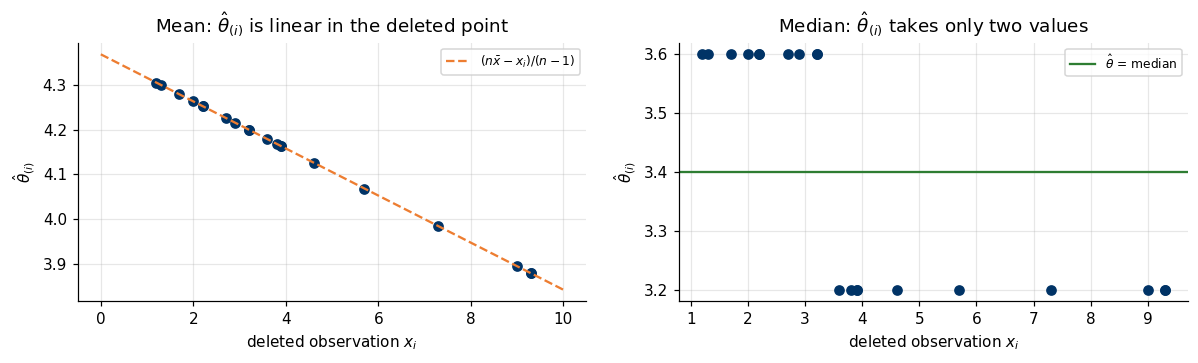

In [ ]:
# ------------------------------------------------------------------
# 4.2-4.3  Jackknife the mean and the median of the hospital data.
# ------------------------------------------------------------------
jk_mean = jackknife(los, np.mean)
jk_med = jackknife(los, np.median)

print("MEAN")
print(f"  theta_(i) = (n x_bar - x_i)/(n-1) for every i : "
      f"{np.allclose(jk_mean['theta_i'], (n_los * los.mean() - los) / (n_los - 1))}")
print(f"  jackknife bias = {jk_mean['bias']:.2e}   (zero up to rounding)")
print(f"  jackknife SE   = {jk_mean['se']:.6f}")
print(f"  s / sqrt(n)    = {se_classical:.6f}")
print(f"  pseudo-values are the data: {np.allclose(jk_mean['pseudo'], los)}")

def se_jack_median_even(X):
    """Jackknife SE of the median along the last axis (n even), by the one-gap formula."""
    n = X.shape[-1]; m = n // 2
    part = np.partition(X, [m - 1, m], axis=-1)        # x_(m) and x_(m+1), no full sort
    return np.sqrt(n - 1) / 2 * (part[..., m] - part[..., m - 1])

print("\nMEDIAN")
print(f"  distinct theta_(i): {np.unique(jk_med['theta_i'])}")
print(f"  jackknife bias = {jk_med['bias']:.4f},  jackknife SE = {jk_med['se']:.4f}")
print(f"  one-gap formula   = {se_jack_median_even(los):.4f}")
print(f"  bootstrap SE (Part 2) = {reps_med.std(ddof=1):.4f}")

# --- intervals and tests of H0: 3 days ------------------------------
inf_mean = jack_inference(jk_mean, MU0)
inf_med = jack_inference(jk_med, MU0)
t_ci = stats.ttest_1samp(los, MU0).confidence_interval()
display(pd.DataFrame({
    "SE": [jk_mean["se"], jk_med["se"]],
    "bias": [jk_mean["bias"], jk_med["bias"]],
    "jackknife 95% CI": [f"[{inf_mean['ci'][0]:.3f}, {inf_mean['ci'][1]:.3f}]",
                         f"[{inf_med['ci'][0]:.3f}, {inf_med['ci'][1]:.3f}]"],
    "jackknife p (H0: 3 days)": [inf_mean["p"], inf_med["p"]],
    "compare with": [f"t-test: CI [{t_ci.low:.3f}, {t_ci.high:.3f}], p = {p_t:.4f}",
                     f"bootstrap: CI {part2.loc['median (LOS)', 'percentile 95% CI']}, p = {p_med:.4f}"],
}, index=["mean", "median"]).round(4))

for s, jk, inf in [("mean (LOS)", jk_mean, inf_mean), ("median (LOS)", jk_med, inf_med)]:
    record(s, "jackknife", jk["theta_hat"], jk["se"], jk["bias"], inf["ci"],
           "mu = 3" if s.startswith("mean") else "m = 3", inf["p"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(los, jk_mean["theta_i"], "o", color=BLUE)
xx = np.array([0, 10])
ax[0].plot(xx, (n_los * los.mean() - xx) / (n_los - 1), "--", color=ORANGE, lw=1.5,
           label=r"$(n\bar x - x_i)/(n-1)$")
ax[0].set_title(r"Mean: $\hat\theta_{(i)}$ is linear in the deleted point")
ax[0].set_xlabel(r"deleted observation $x_i$"); ax[0].set_ylabel(r"$\hat\theta_{(i)}$")
ax[0].legend(fontsize=8)

ax[1].plot(los, jk_med["theta_i"], "o", color=BLUE)
ax[1].axhline(med_hat, color=GREEN, lw=1.5, label=r"$\hat\theta$ = median")
ax[1].set_title(r"Median: $\hat\theta_{(i)}$ takes only two values")
ax[1].set_xlabel(r"deleted observation $x_i$"); ax[1].set_ylabel(r"$\hat\theta_{(i)}$")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice.** For the mean the jackknife reproduces $s/\sqrt n$, the $t$ interval and the
$t$-test $p$-value to every printed digit, and the left panel shows why: $\hat\theta_{(i)}$ is
exactly linear in $x_i$, and the jackknife is built on a linear approximation (slide 34: *good
for smooth statistics*). For the median the right panel is a step with two levels. The
jackknife SE, about 0.87, is far above the bootstrap's 0.50, so its interval is much wider and its
$p$-value larger. Which one is wrong? The next section answers that with a known truth.

### 4.4 Why the jackknife fails for the median (slide 34)

The one-gap formula explains the failure. A single spacing between neighbouring order statistics
near the median satisfies $n f(m)\,\big(x_{(m+1)}-x_{(m)}\big) \xrightarrow{d} \mathrm{Exp}(1)$,
while the true SE is $\approx 1/\{2f(m)\sqrt n\}$. Dividing,

$$\frac{\widehat{\mathrm{se}}_{\text{jack}}}{\mathrm{se}} \;\xrightarrow{d}\; \mathrm{Exp}(1)
\qquad\Big(\text{equivalently } \widehat{\mathrm{se}}^2_{\text{jack}}/\mathrm{se}^2 \to (\chi^2_2/2)^2;\ \text{Efron, 1982}\Big).$$

The ratio is right *on average*, but it never settles down to 1 as $n$ grows: the estimator is
**inconsistent**. We check this on $N(0,1)$ data with $n = 20, 200, 2000$ and $R = 2000$ data sets
each (the true SE is the SD of the 2000 medians), and compare with the jackknife for the mean and
the bootstrap for the median.

The same simulation measures what this does to inference: the **coverage** of each nominal 95%
interval (how often it contains the true value 0). A test that rejects when the interval
excludes $\theta_0$ has size $1 - \text{coverage}$, so coverage also tells us whether the
$p$-values can be trusted. If the SE ratio is $E \sim \mathrm{Exp}(1)$, the jackknife interval
covers with probability $E\big[2\Phi(1.96E) - 1\big] \approx 0.69$, far below 0.95.

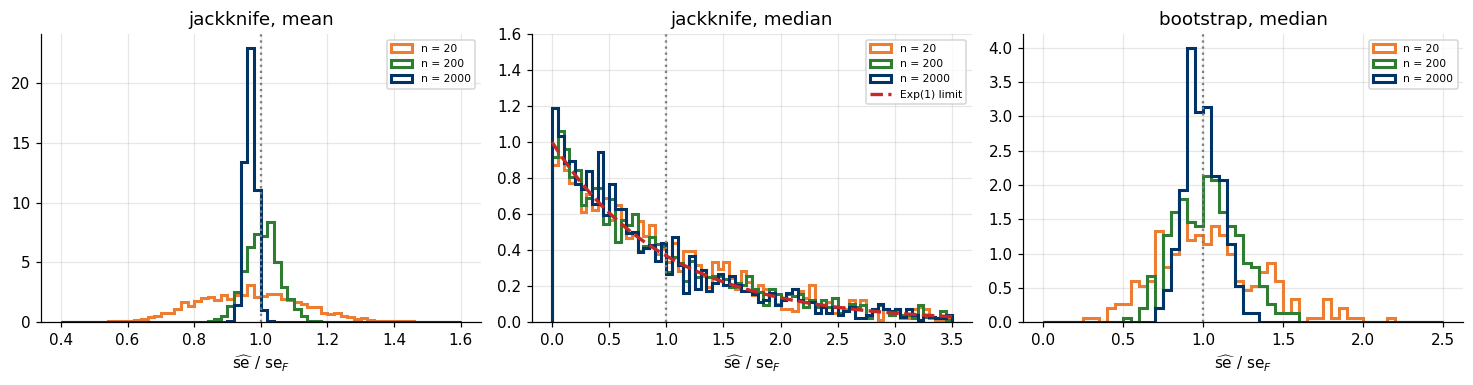

,n = 20,n = 200,n = 2000,Exp(1) limit
"SD of ratio: jackknife, mean",0.158,0.051,0.015,NaN
"SD of ratio: jackknife, median",0.878,1.013,0.943,1.000
"P(ratio < 0.5): jackknife, median",0.368,0.386,0.416,0.393
"P(ratio > 2): jackknife, median",0.121,0.144,0.125,0.135
"SD of ratio: bootstrap, median",0.324,0.196,0.113,NaN
"95% CI coverage: jackknife t interval, mean",0.954,0.954,0.945,NaN
"95% CI coverage: jackknife t interval, median",0.735,0.703,0.678,0.695
"95% CI coverage: bootstrap percentile, median",0.910,0.943,0.930,NaN


In [ ]:
# ------------------------------------------------------------------
# 4.4  SE ratios as n grows: jackknife (mean), jackknife (median), bootstrap (median).
# ------------------------------------------------------------------
ns_jk = [20, 200, 2000]
R_jk, R_bt, B_bt = 2000, 300, 300
res, cover = {}, {}
for n in ns_jk:
    X = rng.standard_normal((R_jk, n))                 # true mean = true median = 0
    xbar, med = X.mean(axis=1), np.median(X, axis=1)
    se_jk_mean = X.std(axis=1, ddof=1) / np.sqrt(n)    # jackknife SE of the mean = s/sqrt(n) (5.2)
    se_jk_med = se_jack_median_even(X)                 # one-gap formula (5.3); bias_jack = 0 for even n
    tq = stats.t.ppf(0.975, df=n - 1)

    boot_se, boot_cover = [], []
    for x in X[:R_bt]:
        m_star = np.median(x[rng.integers(0, n, (B_bt, n))], axis=1)
        boot_se.append(m_star.std(ddof=1))
        lo, hi = np.quantile(m_star, [0.025, 0.975])
        boot_cover.append(lo <= 0 <= hi)

    res[n] = {
        "jackknife, mean":   se_jk_mean / xbar.std(),
        "jackknife, median": se_jk_med / med.std(),
        "bootstrap, median": np.array(boot_se) / med.std(),
    }
    cover[n] = {
        "jackknife t interval, mean":   np.mean(np.abs(xbar) <= tq * se_jk_mean),
        "jackknife t interval, median": np.mean(np.abs(med) <= tq * se_jk_med),
        "bootstrap percentile, median": np.mean(boot_cover),
    }

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
panel_bins = {"jackknife, mean": np.linspace(0.4, 1.6, 61),
              "jackknife, median": np.linspace(0, 3.5, 71),
              "bootstrap, median": np.linspace(0, 2.5, 51)}
for j, key in enumerate(panel_bins):
    for n, c in zip(ns_jk, [ORANGE, GREEN, BLUE]):
        ax[j].hist(res[n][key], bins=panel_bins[key], density=True, histtype="step", lw=2, color=c,
                   label=f"n = {n}")
    ax[j].axvline(1.0, color="gray", ls=":", lw=1.5)
    ax[j].set_title(key); ax[j].set_xlabel(r"$\widehat{\mathrm{se}}\ /\ \mathrm{se}_F$")
g = np.linspace(0, 3.5, 300)
ax[1].plot(g, np.exp(-g), color=RED, ls="--", lw=2.2, label="Exp(1) limit")
ax[1].set_ylim(0, 1.6)
for a in ax:
    a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# limiting coverage of the jackknife median interval: E[2 Phi(1.96 E) - 1] with E ~ Exp(1)
limit_cov = integrate.quad(lambda e: (2 * stats.norm.cdf(1.96 * e) - 1) * np.exp(-e), 0, np.inf)[0]
tbl = pd.DataFrame({n: {"SD of ratio: jackknife, mean": res[n]["jackknife, mean"].std(),
                        "SD of ratio: jackknife, median": res[n]["jackknife, median"].std(),
                        "P(ratio < 0.5): jackknife, median": (res[n]["jackknife, median"] < 0.5).mean(),
                        "P(ratio > 2): jackknife, median": (res[n]["jackknife, median"] > 2).mean(),
                        "SD of ratio: bootstrap, median": res[n]["bootstrap, median"].std(),
                        **{f"95% CI coverage: {k}": v for k, v in cover[n].items()}}
                    for n in ns_jk}).round(3).rename(columns=lambda n: f"n = {n}")
tbl["Exp(1) limit"] = [np.nan, 1.0, 1 - np.exp(-0.5), np.exp(-2), np.nan, np.nan, limit_cov, np.nan]
display(tbl.round(3))

**What to notice.**

* **Jackknife, mean:** the histograms tighten around 1 as $n$ grows. The SD of the ratio falls
  like $1/\sqrt n$.
* **Jackknife, median:** the three histograms lie on top of each other and on the Exp(1)
  curve. At *every* sample size there is about a 39% chance that the jackknife SE is less than
  half the truth, and about a 14% chance ($e^{-2}$) that it is more than double. More data does
  not help.
* **Bootstrap, median:** consistent. It tightens around 1, though slowly (its relative error
  shrinks only like $n^{-1/4}$; Hall & Martin, 1988).
* **Coverage.** The jackknife $t$ interval for the mean covers about 95% of the time, as it
  should (it *is* the $t$ interval). For the median it covers only about 70% at every $n$, close
  to the Exp(1) prediction, so a jackknife "5% test" for the median rejects a true $H_0$ roughly
  30% of the time. The bootstrap percentile interval stays near 95%.

The delete-$d$ jackknife, which leaves out $d$ points at a time with $\sqrt n < d < n$, repairs
this (slide 34). *Try* implementing it on random subsets as an extension.